# Exploratory Data Analysis — Individual Assignment

## Purpose

In the previous group activity, your group proposed three simple questions, three complex questions, and one proxy question about a dataset. In this assignment, you will independently investigate that dataset. Your goal is not to produce as many statistics or plots as possible, but to use appropriate evidence to understand the data, evaluate selected questions, identify limitations, and prepare for a subsequent group discussion.

A good EDA is an investigation, not a checklist. Some analyses suggested below may not be appropriate for your dataset. Justify your choices. It is valid to conclude that the available data cannot answer a question.

## 1. Identification

**Name: Rafael Guimarães Dias / Rodrigo Barboza Dias**  
**NUSP: 14804152 / 12435814**  
**Group Number: 5**  
**Dataset: Dataset 8 — Used Cars (Cars.com, April 2023)**  
**Dataset source (URL or reference): https://www.kaggle.com/datasets/andreinovikov/used-cars-dataset**

## 2. Dataset context

Describe the dataset in your own words. Address, whenever the information is available:

- What does one row represent? What is the unit of observation?
- What population, phenomenon, or process is represented?
- How, when, and by whom were the data collected?
- What are the temporal and geographic coverage?
- Is the dataset a sample, a census, or a collection generated by another process?
- What important aspects of the population or phenomenon may be absent?

**Your answer:**
- Cada linha representa um anúncio individual de oferta de um veículo usado (listing) publicado na plataforma Cars.com. A unidade de observação é, portanto, um registro de anúncio; como o CSV não possui um identificador único, não é possível garantir que cada linha corresponda a um veículo diferente.
- O dataset representa uma coleção de anúncios do mercado digital de veículos usados nos Estados Unidos, capturada em um determinado momento. Ele descreve principalmente as características dos veículos e os preços pedidos pelos vendedores.
- Os dados foram obtidos por web scraping do portal público Cars.com e disponibilizados como o Dataset 8 — Used Cars (Cars.com, April 2023). A coleta corresponde ao contexto de abril de 2023.
- A cobertura temporal da coleta é transversal: os anúncios foram observados em abril de 2023, enquanto a variável year representa o ano-modelo do veículo. Portanto, diferenças entre anos-modelo não devem ser interpretadas como uma série histórica de vendas ou de anúncios observados em diferentes anos.
- O CSV fornecido não contém uma coluna location, state, city ou zip. Assim, embora o conjunto esteja associado ao mercado americano pela descrição de sua coleta, a cobertura geográfica não pode ser analisada diretamente a partir dos registros disponíveis.
- O dataset registra principalmente o preço anunciado (asking price), e não o preço final efetivamente pago em uma transação. Também não há informações sobre compradores, renda, comportamento de busca, tempo de permanência do anúncio ou um identificador único que permita rastrear republicações.

## 3. Load the data and document reproducibility

Load the dataset using a relative path or a documented download procedure. Import all required libraries here. Your notebook must run from beginning to end in the correct order. Do not hide warnings without explaining why they are harmless.

In [1]:
import sys
import platform
from pathlib import Path
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("--- Informações de reprodução ---")
print(f"Python: {sys.version.split()[0]}")
print(f"Plataforma: {platform.platform()}")
print(f"Pandas: {version('pandas')}")
print(f"NumPy: {version('numpy')}")
print(f"Matplotlib: {version('matplotlib')}")
print(f"Seaborn: {version('seaborn')}")

sns.set_theme(style="whitegrid")

URL_DADOS = (
    "https://raw.githubusercontent.com/rodrigobarbozadias/"
    "MAC5865---Ci-ncia-e-Engenharia-de-Dados/main/EP1/cars.csv.gz"
)
arquivo_csv = Path("cars.csv")

if not arquivo_csv.exists():
    import gzip, shutil, urllib.request
    print("cars.csv não encontrado localmente; baixando do GitHub...")
    with urllib.request.urlopen(URL_DADOS) as resposta, \
         gzip.GzipFile(fileobj=resposta) as compactado, \
         open(arquivo_csv, "wb") as destino:
        shutil.copyfileobj(compactado, destino)

df_raw = pd.read_csv(arquivo_csv)

--- Informações de reprodução ---
Python: 3.13.16
Plataforma: Linux-6.6.122+-x86_64-with-glibc2.39
Pandas: 2.2.3
NumPy: 2.1.3
Matplotlib: 3.10.0
Seaborn: 0.13.2


In [2]:
import hashlib

with open(arquivo_csv, "rb") as arquivo:
    sha256_csv = hashlib.file_digest(arquivo, "sha256").hexdigest()

versoes = {
    pacote: version(pacote)
    for pacote in ["pandas", "numpy", "matplotlib", "seaborn"]
}

display(pd.Series(versoes, name="versao").to_frame())

print("SHA-256 do cars.csv:", sha256_csv)

,versao
pandas,2.2.3
numpy,2.1.3
matplotlib,3.10.0
seaborn,0.13.2


SHA-256 do cars.csv: b66592aefd315e73fe84e984f92198c50707d4963a369b7c793ad21e1d455b07


## 4. Initial data audit

Inspect the structure and quality of the data before analyzing the questions. Report and interpret:

- number of rows and columns;
- the meaning and type of relevant variables (quantitative, nominal, ordinal, date/time, text, or identifier);
- missing values, duplicated observations, and unexpected categories or values;
- whether numeric codes are actually categories or identifiers;
- possible inconsistencies in units, formats, ranges, or labels.

Do not automatically delete missing, duplicated, or unusual observations. First investigate what they mean.

In [3]:
print("--- DIMENSÕES E ESTRUTURA ---")
print(f"Linhas: {df_raw.shape[0]:,}")
print(f"Colunas: {df_raw.shape[1]:,}\n")

df_raw.info(verbose=False, show_counts=True)

print("\n--- AMOSTRA DOS DADOS ---")
display(df_raw.head(3))

print("\n--- VALORES FALTANTES ---")
missing = df_raw.isna().sum()
missing_pct = missing / len(df_raw) * 100

missing_summary = pd.DataFrame({
    "Nulos": missing,
    "Porcentagem (%)": missing_pct.round(2)
})

display(
    missing_summary[missing_summary["Nulos"] > 0]
    .sort_values("Porcentagem (%)", ascending=False)
)

print("\n--- DUPLICATAS COMPLETAS ---")
dup_count = df_raw.duplicated().sum()
print(
    f"Linhas idênticas duplicadas: "
    f"{dup_count:,} ({dup_count / len(df_raw) * 100:.2f}%)"
)

print("\n--- RESUMO DAS VARIÁVEIS NUMÉRICAS ---")
numeric_cols = df_raw.select_dtypes(include=[np.number]).columns.tolist()
display(df_raw[numeric_cols].describe().T)

print("\n--- CARDINALIDADE DE VARIÁVEIS CATEGÓRICAS ---")
categoricas_relevantes = [
    "manufacturer",
    "model",
    "fuel_type",
    "transmission",
    "drivetrain",
    "exterior_color",
    "interior_color",
    "accidents_or_damage",
    "one_owner",
    "personal_use_only"
]

for coluna in categoricas_relevantes:
    if coluna in df_raw.columns:
        print(
            f"{coluna}: {df_raw[coluna].nunique(dropna=True):,} "
            f"categorias distintas; "
            f"{df_raw[coluna].isna().sum():,} nulos"
        )

print("\n--- VALORES DAS VARIÁVEIS DE BAIXA CARDINALIDADE ---")
for coluna in categoricas_relevantes:
    if coluna in df_raw.columns:
        n_unicos = df_raw[coluna].nunique(dropna=True)
        if n_unicos <= 20:
            print(f"\n{coluna}:")
            display(
                df_raw[coluna]
                .value_counts(dropna=False)
                .rename("n")
                .to_frame()
            )

print("\n--- VERIFICAÇÃO DE CÓDIGOS NUMÉRICOS DE BAIXA CARDINALIDADE ---")
for coluna in numeric_cols:
    n_unicos = df_raw[coluna].nunique(dropna=True)
    if n_unicos <= 20:
        print(
            f"{coluna}: {n_unicos} valores distintos "
            f"(avaliar se é categoria/ordinal em vez de medida contínua)"
        )

--- DIMENSÕES E ESTRUTURA ---
Linhas: 762,091
Colunas: 20

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 762091 entries, 0 to 762090
Columns: 20 entries, manufacturer to price
dtypes: float64(9), int64(1), object(10)
memory usage: 116.3+ MB

--- AMOSTRA DOS DADOS ---


,manufacturer,model,year,mileage,engine,transmission,drivetrain,fuel_type,mpg,exterior_color,interior_color,accidents_or_damage,one_owner,personal_use_only,seller_name,seller_rating,driver_rating,driver_reviews_num,price_drop,price
0,Acura,ILX Hybrid 1.5L,2013,92945.0,"1.5L I-4 i-VTEC variable valve control, engine...",Automatic,Front-wheel Drive,Gasoline,39-38,Black,Parchment,0.0,0.0,0.0,Iconic Coach,NaN,4.4,12.0,300.0,13988.0
1,Acura,ILX Hybrid 1.5L,2013,47645.0,1.5L I4 8V MPFI SOHC Hybrid,Automatic CVT,Front-wheel Drive,Hybrid,39-38,Gray,Ebony,1.0,1.0,1.0,Kars Today,NaN,4.4,12.0,NaN,17995.0
2,Acura,ILX Hybrid 1.5L,2013,53422.0,1.5L I4 8V MPFI SOHC Hybrid,Automatic CVT,Front-wheel Drive,Hybrid,39-38,Bellanova White Pearl,Ebony,0.0,1.0,1.0,Weiss Toyota of South County,4.3,4.4,12.0,500.0,17000.0



--- VALORES FALTANTES ---


,Nulos,Porcentagem (%)
price_drop,351979,46.19
seller_rating,213973,28.08
mpg,142071,18.64
interior_color,56975,7.48
driver_rating,31632,4.15
one_owner,31483,4.13
personal_use_only,24852,3.26
accidents_or_damage,24212,3.18
fuel_type,22927,3.01
drivetrain,21562,2.83



--- DUPLICATAS COMPLETAS ---
Linhas idênticas duplicadas: 9,145 (1.20%)

--- RESUMO DAS VARIÁVEIS NUMÉRICAS ---


...


one_owner:


,n
one_owner,
1.0,410579
0.0,320029
NaN,31483



personal_use_only:


,n
personal_use_only,
1.0,484522
0.0,252717
NaN,24852



--- VERIFICAÇÃO DE CÓDIGOS NUMÉRICOS DE BAIXA CARDINALIDADE ---
accidents_or_damage: 2 valores distintos (avaliar se é categoria/ordinal em vez de medida contínua)
one_owner: 2 valores distintos (avaliar se é categoria/ordinal em vez de medida contínua)
personal_use_only: 2 valores distintos (avaliar se é categoria/ordinal em vez de medida contínua)


### Audit findings and data-preparation decisions

Summarize what you found. For every modification, state **what was changed, why it was changed, and how many observations were affected**. Distinguish between correction, exclusion, transformation, and creation of a derived variable.

**Your answer:**

**Achados da Auditoria:**

- O dataset possui 762.091 registros e 20 variáveis. A unidade de observação é um anúncio, e não há identificador único que permita verificar a unicidade dos veículos.

- Foram encontradas 9.145 linhas idênticas duplicadas. Essas cópias são registros exatamente iguais; não é possível afirmar, apenas a partir do CSV, que elas correspondam a republicações de anúncios, pois não existe identificador do anúncio ou do veículo.

- Há valores ausentes em várias variáveis, principalmente em price_drop, seller_rating e mpg. A ausência não foi preenchida artificialmente. Em particular, os 506 registros com mileage ausente não fornecem informação para as análises que dependem diretamente de quilometragem.

- As variáveis manufacturer, model, fuel_type, transmission, drivetrain e outras semelhantes são categóricas, enquanto price e mileage são quantitativas. year representa o ano-modelo e, portanto, é uma variável temporal/ordinal para as comparações entre safras de veículos. Não foram identificadas variáveis numéricas que devam ser tratadas como identificadores.

- Também foram observadas categorias textuais com diferentes níveis de granularidade, especialmente em model. Nesse campo, versões e acabamentos podem aparecer como rótulos distintos, de modo que “modelo” no restante da análise deve ser entendido como o rótulo presente no arquivo.

**Decisões de Preparação:**

- Retirada de duplicatas completas — exclusão:
Foram removidas 9.145 cópias idênticas. A justificativa é evitar que observações literalmente repetidas recebam peso duplicado nas análises. Como não há identificador único, essa operação não garante que os registros restantes correspondam a veículos únicos.

- Filtro de preço — exclusão:
Foram mantidos apenas registros com 1.500 <= price <= 250.000 USD. O objetivo é delimitar a análise ao mercado geral de veículos usados e evitar que valores extremamente baixos ou extremamente altos dominem as medidas de posição e dispersão. A presença de registros com preço igual a USD 1 foi observada, mas o CSV não permite afirmar que esses valores sejam necessariamente placeholders de “a combinar”; por isso, eles são apenas excluídos pelo recorte definido, sem atribuir uma causa não comprovada.

- Filtro de ano-modelo — exclusão:
Foram mantidos veículos com 1990 <= year <= 2024. O objetivo é evitar que poucos veículos muito antigos, pertencentes a um segmento potencialmente distinto de carros clássicos ou colecionáveis, dominem comparações destinadas ao mercado geral de usados.

- Filtro de quilometragem — exclusão:
Para o recorte principal, foram mantidos apenas registros com 5 <= mileage <= 400.000. Assim, valores muito baixos e valores extremos de quilometragem não participam das análises quantitativas de mileage. Essa regra é aplicada uniformemente para manter o recorte reproduzível. Os valores ausentes de mileage também ficam fora do recorte porque não fornecem a variável necessária para essa parte da análise; eles permanecem na base original e sua ausência é investigada separadamente.

- Criação de fuel_type_clean — transformação:
Foi criada uma variável derivada para agrupar categorias pouco frequentes de combustível em Other, mantendo separadamente os principais rótulos (Gasoline, Hybrid, Diesel, E85 Flex Fuel e Electric) e distinguindo valores ausentes como Missing. Essa transformação é usada apenas para facilitar visualizações e agrupamentos, enquanto fuel_type original permanece preservada para auditoria.

In [4]:
df = df_raw.copy()

initial_rows = len(df)

# 1. Remoção de duplicatas completas
df = df.drop_duplicates()

duplicatas_removidas = initial_rows - len(df)

print(
    f"Duplicatas completas removidas: "
    f"{duplicatas_removidas:,}"
)

# 2. Recorte de preço
price_filter = (
    (df["price"] >= 1500)
    & (df["price"] <= 250000)
)

# 3. Recorte de ano-modelo
year_filter = (
    (df["year"] >= 1990)
    & (df["year"] <= 2024)
)

# 4. Recorte de quilometragem
mileage_filter = (
    (df["mileage"] >= 5)
    & (df["mileage"] <= 400000)
)

# Aplicação conjunta dos filtros
df_clean = df[
    price_filter
    & year_filter
    & mileage_filter
].copy()

# 5. Variável derivada para combustível
main_fuels = [
    "Gasoline",
    "Hybrid",
    "Diesel",
    "E85 Flex Fuel",
    "Electric"
]

df_clean["fuel_type_clean"] = df_clean["fuel_type"].fillna("Missing")

df_clean.loc[
    ~df_clean["fuel_type_clean"].isin(main_fuels + ["Missing"]),
    "fuel_type_clean"
] = "Other"

print(
    f"Linhas preservadas após auditoria e limpeza: "
    f"{len(df_clean):,} "
    f"({len(df_clean) / initial_rows * 100:.1f}% do original)."
)

Duplicatas completas removidas: 9,145
Linhas preservadas após auditoria e limpeza: 747,141 (98.0% do original).


### Verificação da preparação e da completude

As três etapas abaixo distinguem a retirada de cópias idênticas do recorte numérico. O recorte foi
mantido para continuidade do trabalho; seus limites não comprovam erro nos registros excluídos.

In [5]:
colunas_originais = df_raw.columns.tolist()
base_sem_copias = df_raw.drop_duplicates().copy()
base_recorte = df_clean.loc[:, colunas_originais].copy().reset_index(drop=True)
bases_eda = {
    'Original': df_raw,
    'Sem cópias idênticas': base_sem_copias,
    'Recorte da seção 4': base_recorte
}

resumo_etapas = pd.DataFrame({
    nome: {
        'registros': len(base),
        'pct_da_original': len(base) / len(df_raw) * 100,
        'media_preco_USD': base['price'].mean(),
        'mediana_preco_USD': base['price'].median(),
        'p95_preco_USD': base['price'].quantile(0.95),
        'p99_preco_USD': base['price'].quantile(0.99),
        'min_preco_USD': base['price'].min(),
        'max_preco_USD': base['price'].max(),
        'mediana_milhas': base['mileage'].median(),
        'ano_min': base['year'].min(),
        'ano_max': base['year'].max()
    } for nome, base in bases_eda.items()
}).T
display(resumo_etapas.T.style.format(precision=2, thousands='.', decimal=','))
print(f'Cópias idênticas retiradas: {df_raw.duplicated().sum():,}')
print(f'Registros fora do recorte, após retirar cópias: {len(base_sem_copias)-len(base_recorte):,}')

falhas_filtros = pd.DataFrame({
    'Preço fora de 1.500–250.000 USD': ~base_sem_copias['price'].between(1500, 250000),
    'Ano fora de 1990–2024': ~base_sem_copias['year'].between(1990, 2024),
    'Milhagem fora de 5–400.000 ou ausente': ~base_sem_copias['mileage'].between(5, 400000)
})
display(pd.DataFrame({
    'registros_sinalizados': falhas_filtros.sum(),
    'pct_base_sem_copias': falhas_filtros.mean()*100
}).round(3))
print('Os critérios se sobrepõem: não somar suas contagens.')
assert int(falhas_filtros.any(axis=1).sum()) == len(base_sem_copias)-len(base_recorte)

,Original,Sem cópias idênticas,Recorte da seção 4
registros,"762.091,00","752.946,00","747.141,00"
pct_da_original,"100,00","98,80","98,04"
media_preco_USD,"36.488,98","35.208,99","32.187,40"
mediana_preco_USD,"27.989,00","27.990,00","27.985,00"
p95_preco_USD,"68.846,00","68.783,00","67.991,00"
p99_preco_USD,"109.995,00","109.994,55","106.955,00"
min_preco_USD,"1,00","1,00","1.500,00"
max_preco_USD,"1.000.000.000,00","1.000.000.000,00","250.000,00"
mediana_milhas,"45.596,00","45.614,00","45.774,00"
ano_min,"1.915,00","1.915,00","1.990,00"


Cópias idênticas retiradas: 9,145
Registros fora do recorte, após retirar cópias: 5,805


,registros_sinalizados,pct_base_sem_copias
Preço fora de 1.500–250.000 USD,676,0.090
Ano fora de 1990–2024,3074,0.408
Milhagem fora de 5–400.000 ou ausente,2507,0.333


Os critérios se sobrepõem: não somar suas contagens.


**Resultado:** 762.091 registros originais → 752.946 após retirar **9.145 cópias idênticas** → 747.141
após excluir **5.805 registros** pelos filtros. Os critérios se sobrepõem e suas contagens não devem
ser somadas. Sem identificador, eliminar cópias completas não assegura unicidade de veículos.

**Ressalvas ao texto inicial:** não há preço zero no CSV; preço de USD 1 e cópias idênticas não
comprovam, respectivamente, valor “a combinar” ou republicação.

In [6]:
completude = pd.DataFrame({
    'ausentes_original_n': df_raw.isna().sum(),
    'ausentes_original_pct': df_raw.isna().mean()*100,
    'ausentes_recorte_n': base_recorte.isna().sum(),
    'ausentes_recorte_pct': base_recorte.isna().mean()*100
}).sort_values('ausentes_original_pct', ascending=False)
display(completude.head(8).round(2))

,ausentes_original_n,ausentes_original_pct,ausentes_recorte_n,ausentes_recorte_pct
price_drop,351979,46.19,342902,45.90
seller_rating,213973,28.08,208738,27.94
mpg,142071,18.64,137357,18.38
interior_color,56975,7.48,55009,7.36
driver_rating,31632,4.15,29161,3.90
one_owner,31483,4.13,28332,3.79
personal_use_only,24852,3.26,23578,3.16
accidents_or_damage,24212,3.18,23473,3.14


As maiores ausências na original são `price_drop` (**46,19%**), `seller_rating` (**28,08%**) e `mpg`
(**18,64%**). Os filtros pouco alteram essas taxas. Nulo não equivale a desconto zero ou avaliação
zero. Os **506 nulos de milhagem** deixam o recorte pelo filtro, sem terem sido preenchidos.
O padrão de ausência por combustível é investigado na questão 8.

## 5. Select three questions

Select from your group's previous activity: two **simple questions**, two **complex questions*. For each question, state the unit of analysis, relevant variables, required transformation or aggregation, and why the dataset may or may not provide adequate evidence. Do not silently change a question; record both the original and revised versions.

### Simple question 1
**Original question 1:** Qual a maior, o menor, a média e a mediana dos preços dos carros?

**Unit of analysis:** O anúncio individual de venda de veículo usado (variável contínua `price`).

**Variables and planned evidence:** `price` price, variável quantitativa contínua. Serão calculados mínimo, máximo, média, desvio-padrão, mediana, quartis e intervalo interquartil, acompanhados por visualizações da distribuição.

**Initial concerns or limitations:**  O valor é um preço anunciado (asking price), não necessariamente o preço final da transação. A distribuição pode ser fortemente assimétrica e sensível a veículos de luxo ou valores extremos.

### Simple question 2
**Original question 2:**  Qual a marca com mais modelos a venda?

**Revised question 2:** Qual a fabricante (`manufacturer`) com o maior número de modelos distintos em oferta na plataforma?

**Unit of analysis:**  A fabricante do veículo (`manufacturer`).

**Variables and planned evidence:**  `manufacturer` e `model` (ambas categóricas nominais). Agrupamento por marca contando o número de valores únicos (`nunique()`) de `model`, acompanhado de tabela e gráfico de barras.

**Initial concerns or limitations:**  A coluna `model` no dataset é altamente granular e frequentemente inclui versões ou acabamentos (*trim levels*), o que pode inflar artificialmente a contagem de modelos para montadoras que cadastram muitas variações de um mesmo veículo (ex.: Ford com múltiplos acabamentos de F-150). A pergunta foi refinada para "oferta/anúncios à venda", já que o dataset não registra vendas concretizadas.

### Complex question 1
**Original question 1:**  Existe uma tendência de subida ou descida no número de carros elétricos à venda ao longo dos anos?

**Unit of analysis:**  O ano-modelo (`year`), agregando a contagem de anúncios por tipo de combustível.

**Variables and planned evidence:**  `year` (temporal/ordinal) cruzada com `fuel_type_clean` (categórica). Serão comparadas tanto a contagem absoluta de anúncios elétricos quanto a proporção de elétricos dentro de cada ano-modelo.

**Initial concerns or limitations:**  O conjunto é uma fotografia da oferta em abril de 2023. Portanto, `year` representa ano-modelo e não o ano em que cada anúncio foi observado. Diferenças entre anos-modelo não constituem uma série histórica de vendas ou de oferta.

### Complex question 2 (Proxy)
**Original question 2:**  Como a renda dos possíveis compradores, a partir da localização, influencia a busca por modelos, preços, tipos de carro e combustível?

**Revised question 2:** A localização geográfica do anúncio está associada a diferenças nas medianas de preços e na composição de marcas ou combustíveis?

**Unit of analysis:**  Anúncios agregados por estado/localização geográfica.

**Variables and planned evidence:**  Seriam necessárias variáveis como location, state, city ou zip, além de price, manufacturer e fuel_type_clean. O CSV fornecido, porém, não possui essas informações geográficas.

**Initial concerns or limitations:**  A pergunta original mistura comportamento de busca, demanda e renda dos compradores, nenhuma das quais é observada no dataset. Além disso, a variável geográfica necessária para a versão revisada também não está disponível.

## 6. Explore the relevant variables

Choose summaries appropriate to each variable type:

- quantitative: median, quartiles, mean, standard deviation, range, and/or robust summaries;
- categorical: absolute and relative frequencies;
- ordinal: ordered frequencies and suitable measures of position;
- dates and times: coverage, frequency by period, gaps, and trends;
- identifiers: uniqueness and duplication checks, not means or histograms.

Examine relevant features such as concentration, dispersion, multimodality, gaps, floor/ceiling effects, and unusual observations. Use appropriate visualizations—for example, histograms or ECDFs for quantitative variables, bar charts for categorical variables, and time plots for temporal variables. Every table or plot must have a purpose and a written interpretation.

Preço -> Min: $1,500 | Q1: $19,595 | Mediana: $27,985 | Q3: $39,237 | Média: $32,187 | Max: $250,000 | Desvio: $20,452
Quilometragem -> Min: 5 | Mediana: 45,774 | Média: 55,942 | Max: 398,677 | Desvio: 43,201


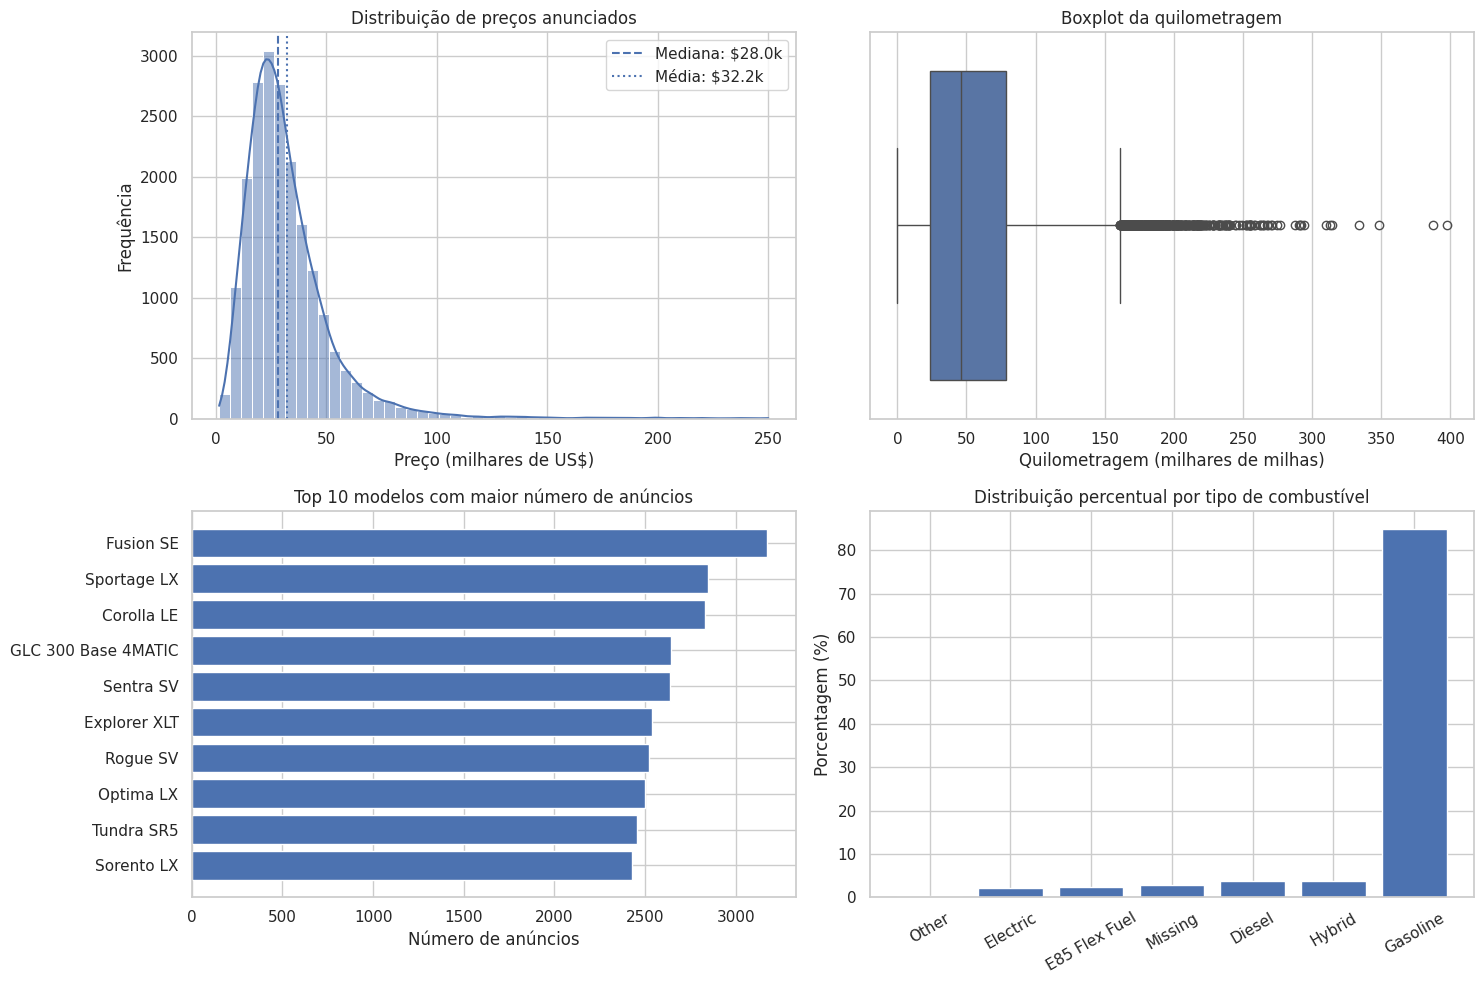

In [7]:
df_sample = df_clean.sample(
    n=min(20000, len(df_clean)),
    random_state=42
)

# 1. Preço
p_mean = df_clean["price"].mean()
p_med = df_clean["price"].median()
p_std = df_clean["price"].std()
p_min = df_clean["price"].min()
p_max = df_clean["price"].max()
p_q1 = df_clean["price"].quantile(0.25)
p_q3 = df_clean["price"].quantile(0.75)

print(
    f"Preço -> "
    f"Min: ${p_min:,.0f} | "
    f"Q1: ${p_q1:,.0f} | "
    f"Mediana: ${p_med:,.0f} | "
    f"Q3: ${p_q3:,.0f} | "
    f"Média: ${p_mean:,.0f} | "
    f"Max: ${p_max:,.0f} | "
    f"Desvio: ${p_std:,.0f}"
)

# 2. Quilometragem
m_mean = df_clean["mileage"].mean()
m_med = df_clean["mileage"].median()
m_std = df_clean["mileage"].std()
m_min = df_clean["mileage"].min()
m_max = df_clean["mileage"].max()

print(
    f"Quilometragem -> "
    f"Min: {m_min:,.0f} | "
    f"Mediana: {m_med:,.0f} | "
    f"Média: {m_mean:,.0f} | "
    f"Max: {m_max:,.0f} | "
    f"Desvio: {m_std:,.0f}"
)

fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 10)
)

# Preço
sns.histplot(
    df_sample["price"] / 1000,
    bins=50,
    kde=True,
    ax=axes[0, 0]
)

axes[0, 0].axvline(
    p_med / 1000,
    linestyle="--",
    label=f"Mediana: ${p_med / 1000:.1f}k"
)

axes[0, 0].axvline(
    p_mean / 1000,
    linestyle=":",
    label=f"Média: ${p_mean / 1000:.1f}k"
)

axes[0, 0].set_title(
    "Distribuição de preços anunciados"
)
axes[0, 0].set_xlabel(
    "Preço (milhares de US$)"
)
axes[0, 0].set_ylabel(
    "Frequência"
)
axes[0, 0].legend()

# Quilometragem
sns.boxplot(
    x=df_sample["mileage"] / 1000,
    ax=axes[0, 1]
)

axes[0, 1].set_title(
    "Boxplot da quilometragem"
)
axes[0, 1].set_xlabel(
    "Quilometragem (milhares de milhas)"
)

# Top 10 modelos mais anunciados
top_models = (
    df_clean["model"]
    .value_counts()
    .head(10)
    .sort_values()
)

axes[1, 0].barh(
    top_models.index,
    top_models.values
)

axes[1, 0].set_title(
    "Top 10 modelos com maior número de anúncios"
)
axes[1, 0].set_xlabel(
    "Número de anúncios"
)

# Tipo de combustível
fuel_pct = (
    df_clean["fuel_type_clean"]
    .value_counts(normalize=True)
    .mul(100)
    .sort_values()
)

axes[1, 1].bar(
    fuel_pct.index,
    fuel_pct.values
)

axes[1, 1].set_title(
    "Distribuição percentual por tipo de combustível"
)
axes[1, 1].set_ylabel(
    "Porcentagem (%)"
)
axes[1, 1].tick_params(
    axis="x",
    rotation=30
)

plt.tight_layout()
plt.show()

### Interpretation of the relevant variables

Explain what the summaries and plots reveal and why it matters for your questions. Avoid merely repeating numbers shown in a table or describing the plotting command.

**Your answer:**
- Preço: A distribuição apresenta forte assimetria à direita. A média de aproximadamente USD 32,2 mil fica acima da mediana, de aproximadamente USD 28,0 mil, porque alguns anúncios de valores muito elevados puxam a média para cima. Para a Pergunta Simples 1, isso torna a mediana e o intervalo interquartil especialmente úteis para descrever o centro e a dispersão típicos da distribuição.

- Quilometragem: A distribuição apresenta concentração na região de quilometragens baixas e médias e uma cauda longa. O recorte adotado limita a análise a valores entre 5 e 400 mil milhas, evitando que valores extremos dominem os resumos. Isso é relevante para as análises de associação entre price e mileage, nas quais diferenças de escala e valores extremos podem influenciar medidas lineares.

- Modelos mais anunciados: O gráfico mostra que alguns poucos rótulos de model concentram grande número de anúncios. Essa concentração fornece contexto para a Pergunta Simples 2, mas não responde à questão sobre diversidade por fabricante: volume de anúncios e número de modelos distintos são medidas diferentes. Como model pode conter versões e acabamentos, a contagem deve ser interpretada como diversidade de rótulos do arquivo.

- Combustível: A gasolina domina a composição do recorte, enquanto elétricos, híbridos e diesel aparecem em grupos menores. Essa diferença de tamanho entre grupos deve ser considerada em comparações por combustível. Em particular, a participação dos elétricos é mais adequadamente examinada por contagem e proporção por ano-modelo do que apenas por frequência absoluta.

As visualizações, portanto, ajudam a definir quais medidas são mais informativas para cada pergunta e mostram que a estrutura da base precisa ser considerada antes de interpretar os resultados.

### Sensibilidade da distribuição de preços

O gráfico compara a região até USD 120 mil em faixas iguais. As porcentagens usam todos os registros
de cada base como denominador; os valores acima da janela continuam na análise e são contados abaixo.

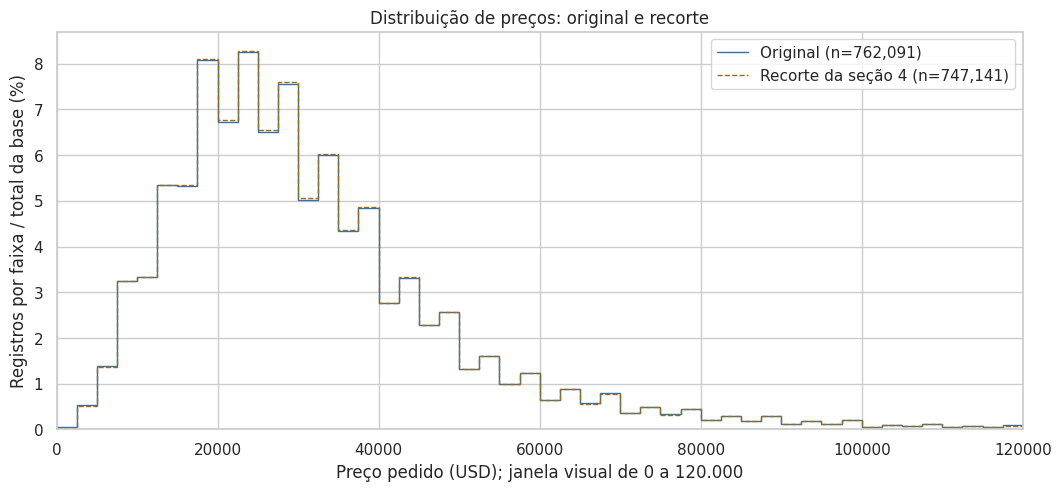

,base,acima_120mil_n,acima_120mil_pct
0,Original,5669,0.744
1,Recorte da seção 4,4799,0.642


In [8]:
limite_visual = 120000
faixas_preco = np.linspace(0, limite_visual, 49)
fig, ax = plt.subplots(figsize=(10.5, 4.8), layout='constrained')
linhas_janela = []
for nome, cor, estilo in [('Original', '#3070B3', '-'),
                          ('Recorte da seção 4', '#9C6B16', '--')]:
    valores = bases_eda[nome]['price'].dropna()
    contagens, _ = np.histogram(valores, bins=faixas_preco)
    ax.stairs(contagens/len(valores)*100, faixas_preco,
              label=f'{nome} (n={len(valores):,})', color=cor, linestyle=estilo)
    linhas_janela.append({'base': nome,
                         'acima_120mil_n': int(valores.gt(limite_visual).sum()),
                         'acima_120mil_pct': valores.gt(limite_visual).mean()*100})
ax.set(title='Distribuição de preços: original e recorte',
       xlabel='Preço pedido (USD); janela visual de 0 a 120.000',
       ylabel='Registros por faixa / total da base (%)', xlim=(0, limite_visual), ylim=(0, None))
ax.ticklabel_format(style='plain', axis='x')
ax.legend()
plt.show()
display(pd.DataFrame(linhas_janela).round(3))

A média muda de USD 36.488,98 na base original para USD 35.208,99 após retirar cópias idênticas e para USD 32.187,40 no recorte analítico. A mediana permanece próxima de USD 28 mil, mostrando que o centro da distribuição é menos sensível às etapas de preparação do que a média.

Sem cópias idênticas, o percentil 99 é USD 109.994,55, muito abaixo do máximo de USD 1 bilhão observado na base antes dos filtros. Isso reforça a importância de investigar os valores extremos separadamente.

O recorte final permanece assimétrico, mas sua média e seus percentis são muito mais representativos da faixa escolhida para caracterizar o mercado geral de anúncios.

Relação com as perguntas: essa análise reforça a escolha da mediana para a Pergunta Simples 1. A contagem dos modelos mais anunciados fornece contexto para a Pergunta Simples 2, mas não mede diversidade por fabricante. Já a análise de combustível e de ano-modelo será usada nas perguntas complexas.

## 7. Relações e subgrupos

### Ano-modelo e presença de elétricos

A participação de anúncios classificados como elétricos é maior em várias safras recentes, mas
não cresce continuamente: passa de **0,69% em 2012** para **4,79% em 2022**, com quedas em anos
intermediários, como 2017 e 2020.

Em 2022 há **3.794 elétricos entre 79.269 anúncios**; em 2023, **833 entre 17.330**. Apesar da queda
na contagem, a participação permanece próxima: **4,79% e 4,81%**, respectivamente.

Isso descreve diferenças entre anos-modelo presentes na mesma coleta. Não demonstra evolução histórica
de vendas ou demanda. Tamanho das safras, seleção da coleta e critérios de combustível limitam a interpretação.

In [9]:
analise_ano = df_clean[['year', 'manufacturer', 'fuel_type_clean']].copy()

analise_ano['eletrico'] = analise_ano['fuel_type_clean'].eq('Electric')
analise_ano['grupo_other'] = analise_ano['fuel_type_clean'].eq('Other')

resumo_ano = analise_ano.groupby('year').agg(
    total_anuncios=('eletrico', 'size'),
    anuncios_eletricos=('eletrico', 'sum'),
    anuncios_other=('grupo_other', 'sum')
).sort_index()

resumo_ano['proporcao_eletricos_pct'] = (
    resumo_ano['anuncios_eletricos'] / resumo_ano['total_anuncios'] * 100
)
display(resumo_ano.loc[[2012, 2016, 2017, 2020, 2022, 2023]].round(3))

,total_anuncios,anuncios_eletricos,anuncios_other,proporcao_eletricos_pct
year,,,,
2012,15274,105,68,0.687
2016,41765,930,79,2.227
2017,51595,672,122,1.302
2020,131798,2106,375,1.598
2022,79269,3794,383,4.786
2023,17330,833,102,4.807


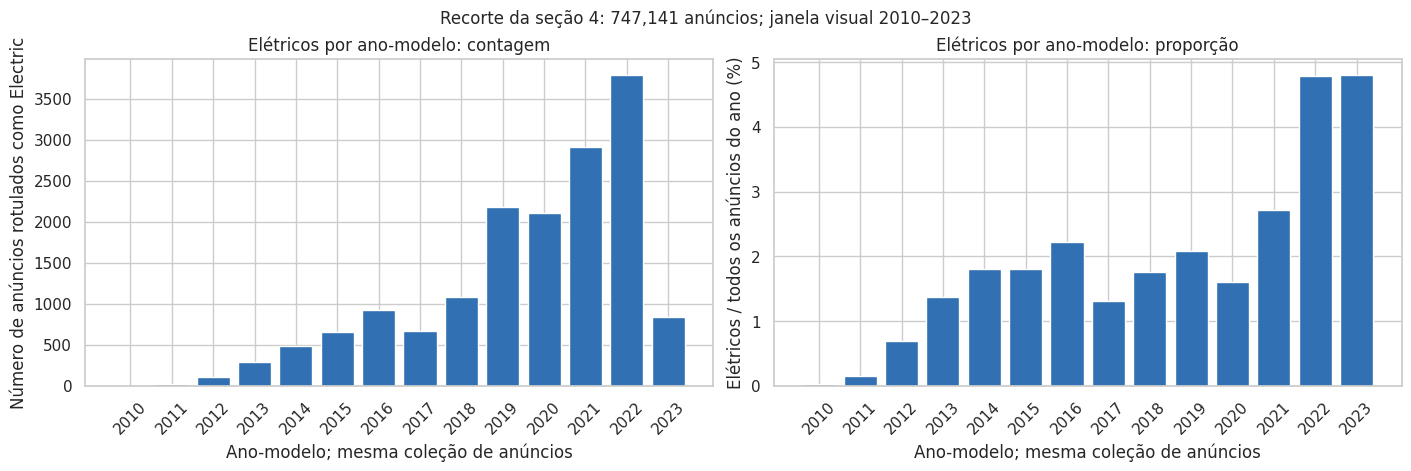

In [10]:
janela_ano = resumo_ano.loc[2010:2023]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), layout='constrained')
axes[0].bar(janela_ano.index, janela_ano['anuncios_eletricos'], color='#3070B3')
axes[0].set_title('Elétricos por ano-modelo: contagem')
axes[0].set_xlabel('Ano-modelo; mesma coleção de anúncios')
axes[0].set_ylabel('Número de anúncios rotulados como Electric')

axes[1].bar(janela_ano.index, janela_ano['proporcao_eletricos_pct'], color='#3070B3')
axes[1].set_title('Elétricos por ano-modelo: proporção')
axes[1].set_xlabel('Ano-modelo; mesma coleção de anúncios')
axes[1].set_ylabel('Elétricos / todos os anúncios do ano (%)')

for ax in axes:
    ax.set_xticks(janela_ano.index)
    ax.tick_params(axis='x', rotation=45)
    ax.set_ylim(bottom=0)
fig.suptitle(f'Recorte da seção 4: {len(df_clean):,} anúncios; janela visual 2010–2023', fontsize=12)
plt.show()

### Fabricante e diversidade de modelos

A **Ford lidera com 970 modelos/versões distintos**, seguida de Mercedes-Benz (936) e Volkswagen (694).
Os modelos da Ford representam **8,47% das 11.448 combinações fabricante–modelo distintas** do recorte.
Seus **77.913 anúncios** representam **10,43% dos 747.141 registros**. Os percentuais medem, respectivamente,
diversidade e volume, e não devem ser confundidos.

As contagens dependem da granularidade dos nomes: acabamentos e versões contam separadamente.
A liderança não significa maior volume de vendas, maior demanda ou maior catálogo real de famílias de veículos.

No recorte há **11.437 rótulos de `model`**, mas **11.448 pares fabricante–modelo**, pois alguns nomes
se repetem entre fabricantes. Para a diversidade, o denominador é 11.448; para anúncios, 747.141.
Alta cardinalidade não justifica agrupar versões sem uma regra documentada.

In [11]:
cardinalidade = pd.DataFrame({
    nome: {
        'fabricantes': base['manufacturer'].nunique(),
        'rotulos_model_sem_fabricante': base['model'].nunique(),
        'pares_fabricante_modelo': base[['manufacturer', 'model']].drop_duplicates().shape[0],
        'rotulos_fuel_type_nao_nulos': base['fuel_type'].nunique()
    } for nome, base in bases_eda.items()
}).T
display(cardinalidade)

,fabricantes,rotulos_model_sem_fabricante,pares_fabricante_modelo,rotulos_fuel_type_nao_nulos
Original,30,12187,12211,36
Sem cópias idênticas,30,12187,12211,36
Recorte da seção 4,30,11437,11448,35


In [12]:
resumo_marcas = df_clean.groupby('manufacturer').agg(
    modelos_distintos=('model', 'nunique'),
    total_anuncios=('model', 'size')
)
total_modelos_distintos = resumo_marcas['modelos_distintos'].sum()
resumo_marcas['participacao_modelos_pct'] = (
    resumo_marcas['modelos_distintos'] / total_modelos_distintos * 100
)
resumo_marcas['participacao_anuncios_pct'] = (
    resumo_marcas['total_anuncios'] / len(df_clean) * 100
)
resumo_marcas = resumo_marcas.sort_values(
    ['modelos_distintos', 'total_anuncios'], ascending=[False, False]
)
display(resumo_marcas.head(10).round(2))

lideres_modelos = resumo_marcas.index[
    resumo_marcas['modelos_distintos'].eq(resumo_marcas['modelos_distintos'].max())
].tolist()
print('Fabricante(s) com o maior número de modelos/versões:', ', '.join(lideres_modelos))

,modelos_distintos,total_anuncios,participacao_modelos_pct,participacao_anuncios_pct
manufacturer,,,,
Ford,970,77913,8.47,10.43
Mercedes-Benz,936,39970,8.18,5.35
Volkswagen,694,24117,6.06,3.23
Toyota,684,58949,5.97,7.89
Chevrolet,667,54296,5.83,7.27
BMW,640,36825,5.59,4.93
Audi,558,17674,4.87,2.37
Volvo,484,9896,4.23,1.32
Lexus,443,20858,3.87,2.79


Fabricante(s) com o maior número de modelos/versões: Ford


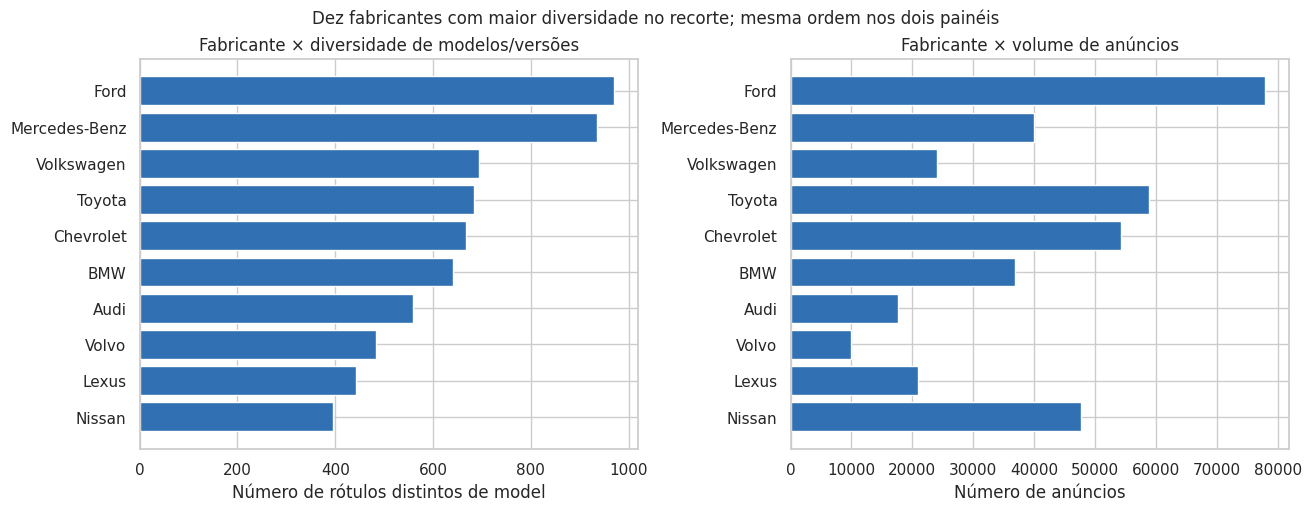

In [13]:
dez_marcas = resumo_marcas.head(10).sort_values('modelos_distintos')
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout='constrained')
axes[0].barh(dez_marcas.index, dez_marcas['modelos_distintos'], color='#3070B3')
axes[0].set_title('Fabricante × diversidade de modelos/versões')
axes[0].set_xlabel('Número de rótulos distintos de model')
axes[1].barh(dez_marcas.index, dez_marcas['total_anuncios'], color='#3070B3')
axes[1].set_title('Fabricante × volume de anúncios')
axes[1].set_xlabel('Número de anúncios')
fig.suptitle('Dez fabricantes com maior diversidade no recorte; mesma ordem nos dois painéis', fontsize=12)
plt.show()

### Localização e perfil socioeconômico

O CSV não contém localização, renda ou registros de busca dos compradores. Portanto, a pergunta
geográfica da seção 5 não pode ser respondida com essa base. A falta de dados não demonstra ausência
de associação. Mesmo com renda média regional, não seria possível atribuí-la diretamente a cada comprador.

In [14]:
print('Colunas disponíveis:', ', '.join(df_raw.columns))
campos = ['location', 'state', 'city', 'zip', 'income', 'buyer_income', 'searches']
display(pd.DataFrame({'campo_procurado': campos, 'presente': [c in df_raw.columns for c in campos]}))

Colunas disponíveis: manufacturer, model, year, mileage, engine, transmission, drivetrain, fuel_type, mpg, exterior_color, interior_color, accidents_or_damage, one_owner, personal_use_only, seller_name, seller_rating, driver_rating, driver_reviews_num, price_drop, price


,campo_procurado,presente
0,location,False
1,state,False
2,city,False
3,zip,False
4,income,False
5,buyer_income,False
6,searches,False


### Relações exploratórias entre preço, ano-modelo e milhagem

Os coeficientes usam todos os pares não nulos, com denominadores na tabela. Pearson resume associação
linear; Spearman considera a ordenação dos valores. Apenas a dispersão usa uma amostra de 20.000
registros, com semente 42; a investigação de valores raros não depende dessa amostra.

,base,variaveis,pares_validos_n,Pearson,Spearman
0,Sem cópias idênticas,price × year,752946,0.0026,0.6510
1,Sem cópias idênticas,price × mileage,752468,-0.0049,-0.6505
2,Sem cópias idênticas,year × mileage,752468,-0.5273,-0.7549
3,Recorte da seção 4,price × year,747141,0.4561,0.6601
4,Recorte da seção 4,price × mileage,747141,-0.5084,-0.6543
5,Recorte da seção 4,year × mileage,747141,-0.6956,-0.7688


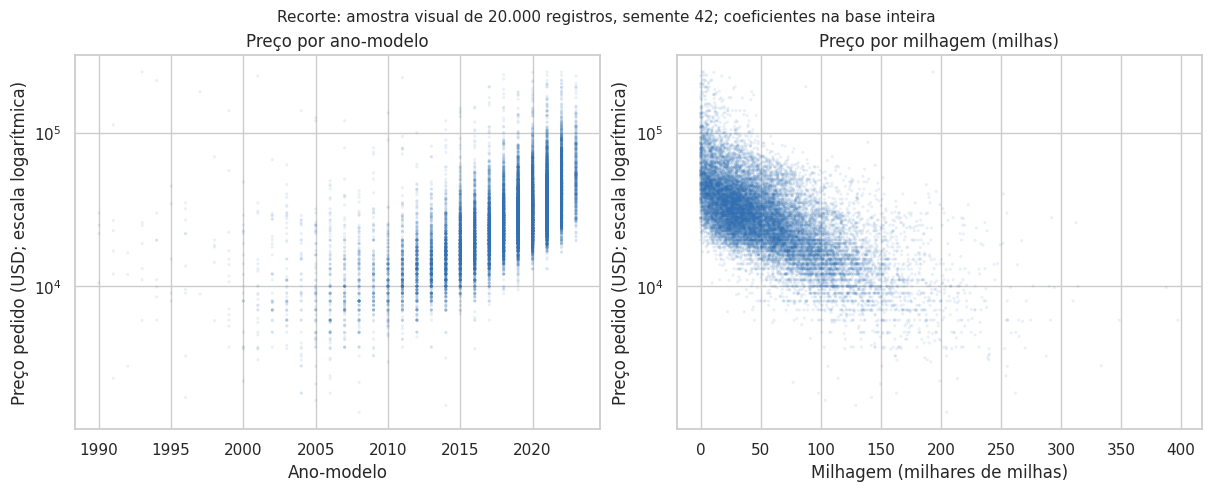

,fabricante,registros,Spearman_preco_milhagem
0,Ford,77913,-0.5889
1,Toyota,58949,-0.6966
2,Chevrolet,54296,-0.5717
3,Nissan,47681,-0.6615
4,Jeep,41054,-0.7671
5,Mercedes-Benz,39970,-0.7127


In [15]:
pares_correlacao = [('price', 'year'), ('price', 'mileage'), ('year', 'mileage')]
linhas_correlacao = []
for nome in ['Sem cópias idênticas', 'Recorte da seção 4']:
    base = bases_eda[nome]
    for primeira, segunda in pares_correlacao:
        pares_validos = base[[primeira, segunda]].dropna()
        linhas_correlacao.append({
            'base': nome, 'variaveis': f'{primeira} × {segunda}',
            'pares_validos_n': len(pares_validos),
            'Pearson': pares_validos[primeira].corr(pares_validos[segunda], method='pearson'),
            'Spearman': pares_validos[primeira].corr(pares_validos[segunda], method='spearman')
        })
correlacoes_eda = pd.DataFrame(linhas_correlacao)
display(correlacoes_eda.round(4))

from matplotlib.ticker import FuncFormatter
amostra_grafico = base_recorte.sample(n=min(20000, len(base_recorte)), random_state=42)
fig, eixos = plt.subplots(1, 2, figsize=(12, 4.8), layout='constrained')
for ax, variavel, rotulo in zip(eixos, ['year', 'mileage'], ['Ano-modelo', 'Milhagem (milhas)']):
    ax.scatter(amostra_grafico[variavel], amostra_grafico['price'],
               s=5, alpha=0.10, color='#3070B3', edgecolors='none', rasterized=True)
    ax.set(xlabel=rotulo, ylabel='Preço pedido (USD; escala logarítmica)', yscale='log',
           title=f'Preço por {rotulo.lower()}')
    if variavel == 'mileage':
        ax.xaxis.set_major_formatter(FuncFormatter(lambda valor, pos: f'{valor/1000:.0f}'))
        ax.set_xlabel('Milhagem (milhares de milhas)')
fig.suptitle('Recorte: amostra visual de 20.000 registros, semente 42; coeficientes na base inteira', fontsize=11)
plt.show()

correlacao_por_fabricante = []
for marca in base_recorte['manufacturer'].value_counts().head(6).index:
    grupo = base_recorte.loc[base_recorte['manufacturer'].eq(marca), ['price', 'mileage']]
    correlacao_por_fabricante.append({
        'fabricante': marca, 'registros': len(grupo),
        'Spearman_preco_milhagem': grupo['price'].corr(grupo['mileage'], method='spearman')
    })
display(pd.DataFrame(correlacao_por_fabricante).round(4))

Antes dos filtros, preço–milhagem apresenta **Pearson −0,0049** e **Spearman −0,6505**; no recorte,
**−0,5084** e **−0,6543**. Portanto, o Pearson quase zero não basta para concluir ausência de associação:
a comparação evidencia sensibilidade à forma da distribuição e aos extremos.

No recorte, preço tende a ser maior em anos-modelo recentes (Spearman **0,6601**) e menor com maior
milhagem. Ano e milhagem também se associam (**−0,7688**). Dentro dos seis fabricantes mais anunciados,
preço–milhagem continua negativo (aproximadamente **−0,57 a −0,77**), com dispersão entre marcas.
Essas relações não controlam todas as características do veículo e não estimam causalmente depreciação.

## 8. Observações e padrões incomuns

### Preços e contexto dos subgrupos

Foram examinados os seis maiores preços e todos os preços de USD 1 antes dos filtros, comparando-os
com outros registros do mesmo fabricante, modelo e ano.

Q1: US$ 19,595.00; Q3: US$ 39,237.00; IQR: US$ 19,642.00
Referência superior global: US$ 68,700.00
Registros acima: 36,219 (4.85%)


,n,mediana_preco,acima_referencia_n,acima_referencia_pct
manufacturer,,,,
Porsche,10665,65998.0,5109,47.90
Land Rover,12010,44897.0,2599,21.64
Mercedes-Benz,39970,39640.5,5771,14.44
Tesla,5821,44992.0,731,12.56
GMC,29094,35647.0,3470,11.93
Cadillac,17283,33996.0,1717,9.93
BMW,36825,33299.0,3274,8.89
RAM,19240,41492.5,1547,8.04


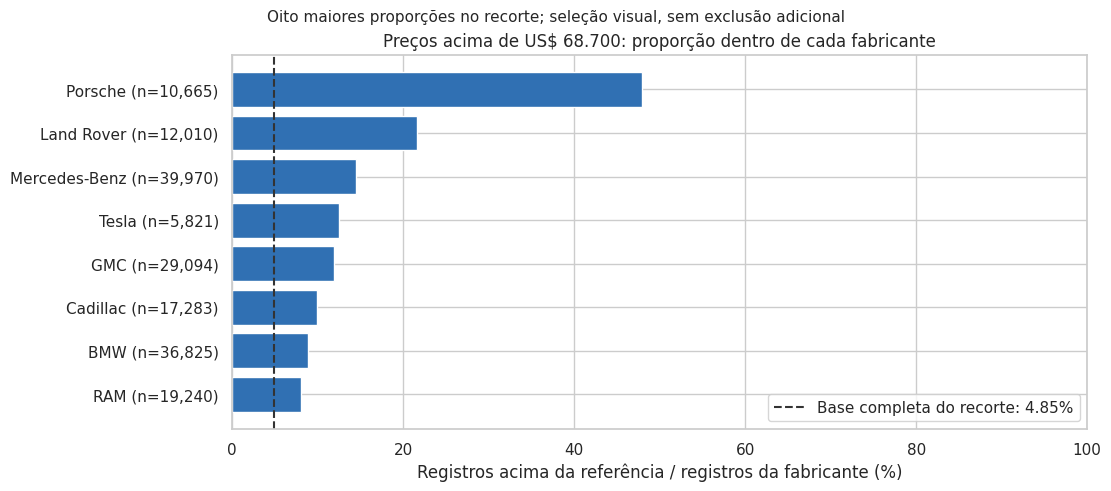

In [16]:
q1 = df_clean['price'].quantile(0.25)
q3 = df_clean['price'].quantile(0.75)
iqr = q3 - q1
limite_superior_iqr = q3 + 1.5 * iqr

precos_contexto = df_clean[['manufacturer', 'price']].copy()
precos_contexto['acima_referencia_global'] = precos_contexto['price'].gt(limite_superior_iqr)
cauda_por_marca = precos_contexto.groupby('manufacturer').agg(
    n=('price', 'size'),
    mediana_preco=('price', 'median'),
    acima_referencia_n=('acima_referencia_global', 'sum')
)
cauda_por_marca['acima_referencia_pct'] = cauda_por_marca['acima_referencia_n'] / cauda_por_marca['n'] * 100
cauda_por_marca = cauda_por_marca.sort_values('acima_referencia_pct', ascending=False)
percentual_global_cauda = precos_contexto['acima_referencia_global'].mean() * 100

print(f'Q1: US$ {q1:,.2f}; Q3: US$ {q3:,.2f}; IQR: US$ {iqr:,.2f}')
print(f'Referência superior global: US$ {limite_superior_iqr:,.2f}')
print(f'Registros acima: {precos_contexto.acima_referencia_global.sum():,} ({percentual_global_cauda:.2f}%)')
display(cauda_por_marca.head(8).round(2))

oito_marcas = cauda_por_marca.head(8).iloc[::-1]
rotulos = [f'{marca} (n={int(linha.n):,})' for marca, linha in oito_marcas.iterrows()]
fig, ax = plt.subplots(figsize=(11, 4.8), layout='constrained')
ax.barh(rotulos, oito_marcas['acima_referencia_pct'], color='#3070B3')
ax.axvline(percentual_global_cauda, color='#333333', linestyle='--',
           label=f'Base completa do recorte: {percentual_global_cauda:.2f}%')
ax.set(title='Preços acima de US$ 68.700: proporção dentro de cada fabricante',
       xlabel='Registros acima da referência / registros da fabricante (%)', xlim=(0, 100))
ax.legend(loc='lower right')
fig.suptitle('Oito maiores proporções no recorte; seleção visual, sem exclusão adicional', fontsize=11)
plt.show()

A referência global de **USD 68.700** sinaliza **36.219 registros (4,85%)**, mas alcança **47,90% dos
anúncios Porsche**, **21,64% dos Land Rover** e **14,44% dos Mercedes-Benz**. Um preço alto no conjunto
pode ser frequente em um subgrupo. Não houve exclusão adicional por esse critério.

In [17]:
base_auditoria = df.copy()
candidatos_preco = pd.concat([
    base_auditoria.nlargest(6, 'price'),
    base_auditoria.loc[base_auditoria['price'].eq(1)]
]).drop_duplicates()

linhas_contexto = []
for indice, caso in candidatos_preco.iterrows():
    mesmo_grupo = (
        base_auditoria['manufacturer'].eq(caso['manufacturer'])
        & base_auditoria['model'].eq(caso['model'])
        & base_auditoria['year'].eq(caso['year'])
        & (base_auditoria.index != indice)
    )
    pares = base_auditoria.loc[mesmo_grupo, 'price']
    mediana_pares = pares.median()
    linhas_contexto.append({
        'manufacturer': caso['manufacturer'], 'model': caso['model'], 'year': caso['year'],
        'preco_candidato': caso['price'], 'n_outros': len(pares),
        'mediana_outros': mediana_pares,
        'razao_preco_mediana': caso['price'] / mediana_pares if len(pares) else np.nan
    })
contexto_candidatos = pd.DataFrame(linhas_contexto)
with pd.option_context('display.max_columns', None):
    display(contexto_candidatos.style.format({
        'preco_candidato': '{:,.2f}', 'mediana_outros': '{:,.2f}',
        'razao_preco_mediana': '{:.6g}'
    }, na_rep='Sem pares'))

,manufacturer,model,year,preco_candidato,n_outros,mediana_outros,razao_preco_mediana
0,Chevrolet,Cobalt LT,2009,"1,000,000,000.00",21,"6,998.00",142898
1,Dodge,Durango Citadel,2018,"1,000,000,000.00",66,"30,662.00",32613.7
2,Ford,Utility Police Interceptor Base,2016,"8,888,889.00",52,"13,893.00",639.811
3,Cadillac,DeVille 77 HOURS ON ENGINES,1963,"4,999,999.00",0,Sem pares,Sem pares
4,RAM,ProMaster 3500 High Roof,2017,"3,490,000.00",9,"35,615.00",97.9924
5,Porsche,Carrera GT,2005,"2,250,000.00",4,"1,497,088.50",1.50292
6,Acura,TLX V6 A-Spec,2018,1.00,41,"26,636.00",3.75432e-05
7,Audi,A4 2.0T Premium,2014,1.00,52,"13,998.00",7.14388e-05
8,Subaru,Legacy 2.5i Limited,2019,1.00,54,"24,506.50",4.08055e-05
9,Volkswagen,Jetta,2007,1.00,0,Sem pares,Sem pares


Os preços de **USD 1 bilhão** de Cobalt LT 2009 e Durango Citadel 2018 contrastam fortemente com as medianas dos outros registros do mesmo fabricante, modelo e ano: **USD 6.998** para o primeiro grupo e **USD 30.662** para o segundo. Já o Carrera GT 2005 de **USD 2,25 milhões** é menos discrepante em relação ao seu grupo, cuja mediana dos quatro pares é **USD 1.497.088,50**.

Para os casos extremos, foram consideradas três interpretações:

1. **Erro de dados:** os valores podem resultar de erros de cadastro, preenchimento ou representação do preço no anúncio. O contraste com os outros registros do mesmo grupo fornece evidência favorável a essa hipótese, embora não a comprove.

2. **Caso raro, mas válido:** alguns veículos podem realmente possuir preços excepcionalmente elevados, especialmente modelos de luxo, esportivos ou colecionáveis. O Carrera GT mostra por que um valor alto não deve ser automaticamente classificado como erro.

3. **Subgrupo ou processo distinto:** determinados anúncios podem pertencer a um segmento especial do mercado, com características de conservação, raridade ou colecionabilidade que não estão representadas nas variáveis utilizadas. A base não contém informação suficiente para confirmar essa interpretação.

**Decisão:** os valores extremos foram mantidos na base de auditoria para não perder informação. Não foram excluídos porque um algoritmo os classificou como *outliers*. Os valores acima de USD 250.000 ficam fora do recorte principal por causa do limite de preço previamente definido, e não como consequência dessa investigação posterior. A confirmação da origem dos valores exigiria consultar os anúncios originais ou outras fontes sobre os veículos.

### Ausência de consumo e classificação de combustível

As taxas usam a base sem cópias, antes dos filtros, e o total de registros de cada combustível.
Mostram-se as sete categorias mais frequentes, mantendo os rótulos originais.

,registros,mpg_ausente_n,mpg_ausente_pct
combustivel_rotulo,,,
Gasoline,637168,68443,10.74
Hybrid,28926,10097,34.91
Diesel,27681,20435,73.82
Ausente,22153,18565,83.80
E85 Flex Fuel,18518,4366,23.58
Electric,16117,16117,100.00
B,1410,1410,100.00


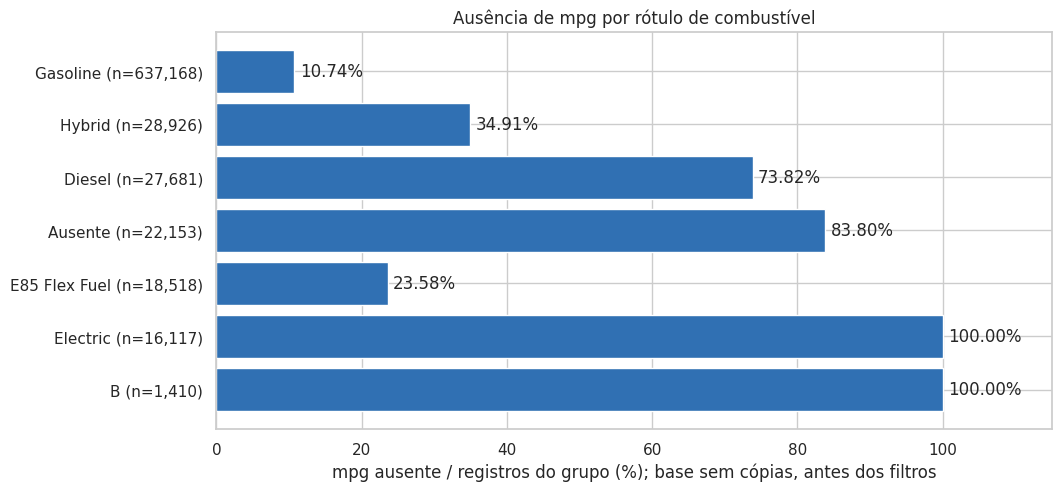

Registros que restariam com dropna() em todas as colunas: 241,257
Elétricos que restariam: 0


In [18]:
auditoria_mpg = base_sem_copias.assign(
    combustivel_rotulo=base_sem_copias['fuel_type'].fillna('Ausente'),
    mpg_ausente=base_sem_copias['mpg'].isna()
)
mpg_por_combustivel = auditoria_mpg.groupby('combustivel_rotulo').agg(
    registros=('price', 'size'),
    mpg_ausente_n=('mpg_ausente', 'sum')
)
mpg_por_combustivel['mpg_ausente_pct'] = (
    mpg_por_combustivel['mpg_ausente_n']/mpg_por_combustivel['registros']*100
)
mpg_por_combustivel = mpg_por_combustivel.sort_values('registros', ascending=False)
display(mpg_por_combustivel.head(7).round(2))

grafico_mpg = mpg_por_combustivel.head(7).iloc[::-1]
rotulos_mpg = [f'{nome} (n={int(linha.registros):,})'
               for nome, linha in grafico_mpg.iterrows()]
fig, ax = plt.subplots(figsize=(10.5, 4.8), layout='constrained')
barras = ax.barh(rotulos_mpg, grafico_mpg['mpg_ausente_pct'], color='#3070B3')
ax.bar_label(barras, labels=[f'{v:.2f}%' for v in grafico_mpg['mpg_ausente_pct']], padding=4)
ax.set(title='Ausência de mpg por rótulo de combustível',
       xlabel='mpg ausente / registros do grupo (%); base sem cópias, antes dos filtros',
       xlim=(0, 115))
plt.show()

completos_em_tudo = base_sem_copias.dropna()
print(f'Registros que restariam com dropna() em todas as colunas: {len(completos_em_tudo):,}')
print('Elétricos que restariam:', int(completos_em_tudo['fuel_type'].eq('Electric').sum()))

`mpg` está ausente em **100% dos 16.117 `Electric`**, **73,82% dos `Diesel`**, **34,91% dos `Hybrid`**
e **10,74% dos `Gasoline`**. A ausência se associa ao grupo, mas o CSV não identifica sua causa.
Remover todas as linhas com qualquer nulo deixaria apenas **241.257 registros e nenhum elétrico**,
comprometendo a pergunta sobre sua participação. Mantêm-se os nulos.

In [19]:
modelo_menciona_hybrid = df_clean['model'].str.contains('Hybrid', case=False, na=False)
print('Modelos com Hybrid no nome:', int(modelo_menciona_hybrid.sum()))
print('Rótulo Hybrid em todo o recorte:', int(df_clean['fuel_type'].eq('Hybrid').sum()))
display(df_clean.loc[modelo_menciona_hybrid, 'fuel_type'].value_counts(dropna=False).rename('n').to_frame())

sinais_adicionais = pd.Series({
    'Até 5 milhas e ano anterior a 2021': int((df['mileage'].le(5) & df['year'].lt(2021)).sum()),
    'Acima de 400 mil milhas': int(df['mileage'].gt(400000).sum()),
    'Ano-modelo 2024': int(df['year'].eq(2024).sum())
}, name='n_antes_dos_filtros')
display(sinais_adicionais.to_frame())
display(df.loc[df['year'].eq(2024), ['manufacturer', 'model', 'year', 'mileage', 'price']])

Modelos com Hybrid no nome: 13975
Rótulo Hybrid em todo o recorte: 28816


,n
fuel_type,
Hybrid,12298
B,738
Gasoline,639
NaN,252
Plug-In Hybrid,33
Regular Unleaded,9
Gas/Electric Hybrid,2
G,1
Premium Unleaded,1


,n_antes_dos_filtros
Até 5 milhas e ano anterior a 2021,1309
Acima de 400 mil milhas,65
Ano-modelo 2024,2


,manufacturer,model,year,mileage,price
499506,Mazda,CX-90 3.3 Turbo Premium Plus,2024,1.0,54920.0
499507,Mazda,CX-90 S Premium Plus,2024,1.0,61920.0


**Hybrid e Gasoline não constituem, por si só, uma contradição demonstrada:** entre os **13.975 registros cujo `model` contém “Hybrid”**, **639** possuem `fuel_type = Gasoline`. O fato de um rótulo aparecer no nome do modelo não garante que o campo de combustível esteja incorreto, pois a nomenclatura comercial pode ser mais ampla do que a classificação utilizada pelo anúncio.

### Interpretações alternativas e decisão

1. **Erro de dados:** alguns registros podem ter sido classificados incorretamente no campo `fuel_type`, ou o nome do modelo pode ter sido preenchido de maneira inconsistente.

2. **Caso raro, mas válido:** o rótulo do modelo pode conter “Hybrid” por convenção comercial, enquanto o anúncio foi classificado de outra maneira. Sem consultar o anúncio original, não é possível rejeitar completamente essa possibilidade.

3. **Subgrupo ou processo distinto:** a combinação pode refletir diferenças no processo de cadastramento, nomenclatura dos veículos ou versões específicas de um mesmo modelo.

**Decisão:** não foram feitas correções ou exclusões com base apenas nessa combinação. O CSV não fornece evidência suficiente para determinar qual das interpretações é correta. Para confirmar a classificação, seriam necessários os anúncios originais ou uma fonte externa que documentasse a motorização de cada veículo.

## 9. Evidências para as perguntas da seção 5

### Simples 1 — maior, menor, média e mediana dos preços

**Evidência e resposta:** no recorte, mínimo de **USD 1.500**, máximo de **USD 250.000**, média de
**USD 32.187,40** e mediana de **USD 27.985**. A mediana descreve um centro próximo de USD 28 mil.

**Limitações:** mínimo e máximo coincidem com os filtros adotados. Os valores são preços pedidos,
não preços de transações. A pergunta fica delimitada aos anúncios do recorte da seção 4.

### Simples 2 — fabricante com mais modelos distintos

**Evidência e resposta:** Ford, com **970 modelos/versões**, à frente de Mercedes-Benz (936) e
Volkswagen (694). Sua participação nos modelos distintos é **8,47%**.

**Limitações:** versões e diferenças de nomenclatura dividem a contagem; mais anúncios aumentam
as chances de se observar versões raras. Mantém-se a pergunta revisada, entendendo “modelo” como o rótulo do arquivo.

### Complexa 1 — elétricos ao longo dos anos

**Evidência e resposta:** a participação de elétricos tende a ser maior em várias safras recentes,
com oscilações. Em 2022 e 2023, são **4,79% e 4,81%**, apesar de contagens bastante diferentes.

**Limitações:** `year` representa ano-modelo, não data de observação do mercado. A conclusão é sobre
composição da oferta nesta coleta, sem demonstrar tendência histórica de vendas ou demanda.

**Reformulação:** como variam quantidade e proporção de anúncios rotulados como elétricos entre os
anos-modelo desta coleção? Para estudar evolução histórica da oferta seriam necessárias coletas
comparáveis em várias datas e identificação dos anúncios; para estudar vendas, dados de transações.

### Complexa 2 — localização como proxy de renda

**Evidência e resposta:** localização, renda e comportamento de busca não estão disponíveis.
A pergunta original e sua revisão geográfica **não podem ser respondidas com este CSV**.

**Limitações:** oferta não mede demanda; renda regional não equivale à renda individual; a localização
do vendedor pode diferir da residência do comprador.

**Dados necessários:** informações complementares de geografia e dados socioeconômicos compatíveis para analisar oferta
regional; dados de compradores e buscas para investigar a pergunta original.

In [20]:
resumo_precos = pd.Series({
    'Minimo_USD': df_clean['price'].min(),
    'Maximo_USD': df_clean['price'].max(),
    'Media_USD': df_clean['price'].mean(),
    'Mediana_USD': df_clean['price'].median(),
    'Q1_USD': df_clean['price'].quantile(0.25),
    'Q3_USD': df_clean['price'].quantile(0.75)
}, name='Valor')
display(resumo_precos.round(2).to_frame())

,Valor
Minimo_USD,1500.0
Maximo_USD,250000.0
Media_USD,32187.4
Mediana_USD,27985.0
Q1_USD,19595.0
Q3_USD,39237.0


## 10. Numeração do material

Não tem enunciado para a questão 10.

## 11. Final individual reflection

### Visão — Rodrigo Barboza Dias
1. **Achado compatível com a expectativa:** A maior participação de elétricos em várias safras recentes, considerando a comparação por ano-modelo e suas oscilações.
2. **Achado que complicou a expectativa:** A contagem de elétricos diminui entre 2022 e 2023, mas sua participação permanece próxima de 4,8%; a leitura muda quando o denominador é considerado.
3. **Pergunta refinada ou inviabilizada:** A ausência de localização inviabilizou a proxy geográfica; a pergunta temporal precisou ser delimitada à composição por ano-modelo.
4. **Limitação principal:** A base descreve uma seleção de anúncios de uma plataforma, não vendas, renda dos compradores ou todo o mercado. O tamanho da base não elimina o viés de seleção.
5. **Nova pergunta:** Dentro do mesmo ano-modelo, como varia a participação de elétricos entre fabricantes?

---

### Visão — Rafael Guimarães Dias
1. **Achado compatível com a expectativa:** A acentuada assimetria à direita na distribuição de preços, confirmando que a cauda longa de veículos de luxo e registros atípicos distorce fortemente a média em relação à mediana, justificando o uso de estatística descritiva robusta.
2. **Achado que complicou a expectativa:** A correlação linear de Pearson entre preço e quilometragem próxima de zero ($-0,0049$) antes dos filtros, que aparentava inexistência de relação, mas que na verdade mascarava uma forte associação monótona negativa revelada pelo coeficiente de Spearman ($-0,6505$) e pela auditoria de valores extremos.
3. **Pergunta refinada ou inviabilizada:** A pergunta complexa de proxy socioeconômica foi inviabilizada pela ausência total de colunas de localização e renda no arquivo; já a pergunta sobre diversidade por fabricante precisou ser refinada para considerar pares distintos de fabricante-modelo em vez de famílias consolidadas de veículos.
4. **Limitação principal:** O dataset retrata exclusivamente um corte transversal de anúncios (*asking prices*) de um único marketplace em abril de 2023, sem registrar o preço efetivo de fechamento das transações, tempo de permanência em estoque ou identificador único para rastrear republicações.
5. **Nova pergunta:** Como se comporta a taxa de depreciação do preço em função da quilometragem quando controlamos conjuntamente o tipo de carroceria (ex.: SUVs versus sedãs) e o tipo de combustível dentro de uma mesma safra?

---

### Síntese Conjunta da Dupla
Embora tenhamos partido de ênfases complementares com uma perspectiva focada no comportamento da distribuição de preços e na sensibilidade das medidas de correlação a valores atípicos, e outra voltada à dinâmica de composição das safras e à importância das proporções relativas em nichos como o de veículos elétricos, convergimos para a constatação central de que o volume amostral expressivo (mais de 740 mil anúncios) não atenua a necessidade de rigor metodológico. Ambos concluímos que métricas paramétricas e interpretações diretas de contagens brutas induzem a leituras equivocadas sobre a oferta, e que a ausência de variáveis geográficas, de dados de transação final e de identificadores únicos impõe limites estritos à extrapolação dos achados, delimitando esta análise estritamente como uma caracterização da vitrine digital da plataforma Cars.com em abril de 2023.

## 12. Preparação para a síntese do grupo

**Possíveis motivos de divergência:** uso de média em vez de mediana; contagem em vez de proporção;
filtros distintos; exclusão de combustível ausente; agrupamento de versões; escalas gráficas diferentes.

**Limitações:** falta de localização, diferença entre o filtro de milhagem descrito e
executado, agrupamento de nulos e rótulos diferentes em `Other`, e confusão entre anúncio, modelo e venda.

**Três visualizações propostas:** distribuição de preços com média e mediana da seção 6; contagem e
proporção de elétricos por ano-modelo; diversidade de modelos e volume de anúncios por fabricante.

**Perguntas revisadas:** estatísticas de preço no recorte; diversidade conforme os rótulos de modelo/versão;
composição por ano-modelo em lugar de tendência histórica. A proxy geográfica permanece sem resposta.
**Nova pergunta:** participação de elétricos por fabricante dentro do mesmo ano-modelo, considerando
tamanho dos grupos e classificação de combustível.



## Submission checklist

- The notebook runs from beginning to end.
- Every table and plot is referenced and interpreted.
- Axes, units, titles, legends, and category labels are readable.
- Data-preparation decisions are documented and quantified.
- Claims do not go beyond the evidence.
- Associations are not presented as causal effects.
- Sources and external code are cited.
- The final synthesis explicitly addresses all questions.